## DATASCIENCE PROJECT: MPG ANALYSIS
#### Team Members: Daniel Rodriguez Medel, Alex Ruiz Costa

#### How to find the data:

Visit this link, https://www.epa.gov/automotive-trends/explore-automotive-trends-data#DetailedData.   
You will find a section at the bottom that says Explore Trends Detailed Data. scroll down a little and find table A: Detailed Real-World Fuel Economy, Vehicle Attribute and Technology Data.   
Make sure the selected is A-1. View by manufcaturer and click on export detailed data by manufacturer (csv).

#### Problem and Data

In our project for DataScience, we will be using a data set that includes different general parameters about cars, the data set has 57 columns and 5661 rows, each column corresponds to a parameter about the car, and each row corresponds to a specific car. The 5661 vehicles are mass production cars made between the year 1975 and the year 2025.  

This data set was found online in the data base of EPA (Enviornmental Protection Agency) - a United States agency whose mission is to protect human health and the environment. They published an Automotive Trends Report, out of which we were able to download our data set.

Out of all the different data we find in our data set, we found most interestng the MPG (Miles Per Gallon). This is a consumption parameter that shows how many miles does a car go for one gallon of fuel. Our target is to predict the MPG based on the other input variables, such as model year, weight, engine power, etc.



#### Exploration
<!-- Check data types, missing values and duplicates. Include two useful plots with titles and units, and explain your observations. -->
In this first section, we will be exploring the data types, missing values and duplicates.  
Firstly, we'll show the raw data nad the data type.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("e1_table_export.csv")

print("Rows and Columns:", df.shape)

display(df.head())

Rows and Columns: (5661, 57)


,Manufacturer,Model Year,Regulatory Class,Vehicle Type,Production (000),Production Share,2-Cycle MPG,Real-World MPG,Real-World MPG_City,Real-World MPG_Hwy,...,Stop/Start of Gasoline ICE non-Hybrids,Cylinder Deactivation of Gasoline ICE Vehicles,Multivalve Engine of Gasoline ICE Vehicles,Variable Valve Timing of Gasoline ICE Vehicles,4 or Fewer Gears,5 Gears,6 Gears,7 Gears,8 Gears,9 or More Gears
0,All,1975,All,All,10224,1.000,15.33300,13.05970,12.01552,14.61167,...,-,-,-,-,0.129,0.010,-,-,-,-
1,All,1976,All,All,12334,1.000,16.70719,14.22136,13.18117,15.73946,...,-,-,-,-,0.788,-,-,-,-,-
2,All,1977,All,All,14123,1.000,17.70553,15.06743,14.00580,16.60587,...,-,-,-,-,-,-,-,-,-,-
3,All,1978,All,All,14448,1.000,18.60678,15.83777,14.68193,17.52390,...,-,-,-,-,0.702,0.073,-,-,-,-
4,All,1979,All,All,13882,1.000,18.69594,15.91271,14.87711,17.39245,...,-,-,-,-,0.938,0.062,-,-,-,-


In [3]:
df.info(57)

<class 'pandas.DataFrame'>
RangeIndex: 5661 entries, 0 to 5660
Data columns (total 57 columns):
 #   Column                                                   Non-Null Count  Dtype
---  ------                                                   --------------  -----
 0   Manufacturer                                             5661 non-null   str  
 1   Model Year                                               5661 non-null   str  
 2   Regulatory Class                                         5661 non-null   str  
 3   Vehicle Type                                             5661 non-null   str  
 4   Production (000)                                         5661 non-null   str  
 5   Production Share                                         5661 non-null   str  
 6   2-Cycle MPG                                              5661 non-null   str  
 7   Real-World MPG                                           5661 non-null   str  
 8   Real-World MPG_City                                      56

#### Preprocessing
<!-- Justify your cleaning decisions and train/test split. Respect time order or groups where relevant. Fit imputation, encoding or scaling only on training data, then apply it to test data.-->
This section belongs to the preparation of the data for further use.

While exploring the data, we discovered that it had some misused information:

Seeing the raw data, we checked the data type, we could see that all the columns are "string" type data, and that is not what we want for all the columns.

The identification of this data as strings is probably because some of the cells have unidentified data inside, such as " - ", among other things, let's correct it.
We will first treat these " - " as absent values and check for different types of data.

Then, we'll show how many columns there are of each data type, and show the first values of our target variable.


In [ ]:
df = pd.read_csv("e1_table_export.csv", na_values=["-"], low_memory=False)  

df.info()  

df.dtypes.value_counts()  

df["Real-World MPG"].head()  

FileNotFoundError: [Errno 2] No such file or directory: 'table_export.csv'

In [ ]:
df.head()

,Manufacturer,Model Year,Regulatory Class,Vehicle Type,Production (000),Production Share,2-Cycle MPG,Real-World MPG,Real-World MPG_City,Real-World MPG_Hwy,...,Stop/Start of Gasoline ICE non-Hybrids,Cylinder Deactivation of Gasoline ICE Vehicles,Multivalve Engine of Gasoline ICE Vehicles,Variable Valve Timing of Gasoline ICE Vehicles,4 or Fewer Gears,5 Gears,6 Gears,7 Gears,8 Gears,9 or More Gears
0,All,1975,All,All,10224.0,1.0,15.33300,13.05970,12.01552,14.61167,...,NaN,NaN,NaN,NaN,0.129,0.010,NaN,NaN,NaN,NaN
1,All,1976,All,All,12334.0,1.0,16.70719,14.22136,13.18117,15.73946,...,NaN,NaN,NaN,NaN,0.788,NaN,NaN,NaN,NaN,NaN
2,All,1977,All,All,14123.0,1.0,17.70553,15.06743,14.00580,16.60587,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,All,1978,All,All,14448.0,1.0,18.60678,15.83777,14.68193,17.52390,...,NaN,NaN,NaN,NaN,0.702,0.073,NaN,NaN,NaN,NaN
4,All,1979,All,All,13882.0,1.0,18.69594,15.91271,14.87711,17.39245,...,NaN,NaN,NaN,NaN,0.938,0.062,NaN,NaN,NaN,NaN


In case we wanted to export the csv file for better reading the data, this is the code we would use:  

    import pandas as pd

    df_excel = pd.read_excel("table_export.csv")

    df_excel.to_csv(
        "table_export_separate.csv",
        sep=";",
        index=False,
        encoding="utf-8-sig")  

    print(f"CSV creado: {df_excel.shape[0]} filas y {df_excel.shape[1]} columnas") 
  

Next, we'll look at the columns that have percentage values, and show some examples.  
After finding these percentage cells, we can replace the percentages for a ratio - this is done with the df_clean operation.  



In [ ]:
df["Fuel Delivery - Diesel"].dropna().unique()[:10]

percentage_with_columns = [column for column in df.columns if df[column].dropna().astype(str).str.contains("%", regex=False).any()] 
for column in percentage_with_columns: 
    print(f"{column}: {df[column].dropna().astype(str).unique()[:5].tolist()}")  

Fuel Delivery - Diesel: ['0.2%', '0.4%', '0.9%', '2.0%', '4.3%']
Fuel Delivery - Battery Electric Vehicle (BEV): ['0.1%', '0.3%', '0.5%', '0.6%', '1.4%']
Powertrain - Gasoline Mild Hybrid/MHEV: ['0.0%', '0.2%', '0.1%', '0.3%', '0.4%']
Powertrain - Gasoline Strong Hybrid/HEV: ['0.1%', '0.3%', '0.8%', '1.2%', '1.9%']
Powertrain - Gasoline with Start/Stop: ['0.6%', '2.3%', '4.9%', '7.0%', '9.4%']
Powertrain - Gasoline without Start/Stop: ['99.8%', '99.6%', '99.1%', '98.0%', '95.7%']


In [ ]:
df_clean = df.copy()  
percentage_columns = ["Fuel Delivery - Diesel",
                      "Fuel Delivery - Battery Electric Vehicle (BEV)",
                      "Powertrain - Gasoline Mild Hybrid/MHEV",
                      "Powertrain - Gasoline Strong Hybrid/HEV",
                      "Powertrain - Gasoline with Start/Stop",
                      "Powertrain - Gasoline without Start/Stop"]  
for column in percentage_columns:  
    df_clean[column] = pd.to_numeric(df_clean[column].str.rstrip("%"), errors="coerce") / 100  
df_clean[percentage_columns].dtypes  

Fuel Delivery - Diesel                            float64
Fuel Delivery - Battery Electric Vehicle (BEV)    float64
Powertrain - Gasoline Mild Hybrid/MHEV            float64
Powertrain - Gasoline Strong Hybrid/HEV           float64
Powertrain - Gasoline with Start/Stop             float64
Powertrain - Gasoline without Start/Stop          float64
dtype: object

In [ ]:
import pandas as pd
df_clean = df.copy()
df_clean = df_clean.replace("-", pd.NA)

In [ ]:
df_clean["Model Year"] = df_clean["Model Year"].str.replace("prelim. ", "", regex=False)
numeric_columns = ["Weight (lbs)", "Model Year", "Production (000)"]

We find the rows where Model Year contains "Prelim.", display those values, remove "Prelim." in df_clean, and check whether any occurrences remain.

In [ ]:
mask_prelim = df["Model Year"].str.contains(
    "Prelim.", regex=False, na=False
)

print(f"Rows with Prelim. before cleaning: {mask_prelim.sum()}")
print(df.loc[mask_prelim, "Model Year"].value_counts())

df_clean["Model Year"] = (
    df_clean["Model Year"]
    .str.replace("Prelim.", "", regex=False)
    .str.strip()
)

prelim_restantes = df_clean["Model Year"].str.contains(
    "Prelim.", regex=False, na=False
).sum()

print(f"Remaining occurrences of Prelim.: {prelim_restantes}")

Rows with Prelim. before cleaning: 111
Model Year
Prelim. 2025    111
Name: count, dtype: int64
Remaining occurrences of Prelim.: 0


We count the cells with the value "All" in each column and display the counts in descending order.

In [ ]:
conteo_all = {}

for columna in df.columns:
    valores = (
        df[columna]
        .astype("string")
        .str.strip()
        .str.casefold()
    )
    cuenta = valores.eq("all").fillna(False).sum()

    if cuenta > 0:
        conteo_all[columna] = cuenta

pd.Series(
    conteo_all,
    name="Rows with value All"
).sort_values(ascending=False)

Regulatory Class    765
Vehicle Type        765
Manufacturer        408
Name: Rows with value All, dtype: int64

We check the "Manufacturer", "Regulatory Class", and "Vehicle Type" columns for rows containing "All". These rows are excluded from df_modelo.

In [ ]:
columnas_all = [
    "Manufacturer",
    "Regulatory Class",
    "Vehicle Type"
]

mask_all = (
    df_clean[columnas_all]
    .astype("string")
    .apply(
        lambda columna: columna.str.strip()
        .str.casefold()
        .eq("all")
        .fillna(False)
    )
    .any(axis=1)
)

print(f"Aggregate rows to exclude: {mask_all.sum()}")

df_modelo = df_clean.loc[~mask_all].copy()

print(f"Rows remaining: {len(df_modelo)}")

Aggregate rows to exclude: 1122
Rows remaining: 4539


We select the columns whose names start with "Powertrain -" and replace their missing values with "0". We then count the missing values before and after this change.

In [ ]:
columnas_powertrain = [
    columna
    for columna in df_modelo.columns
    if columna.startswith("Powertrain - ")
]

ausentes_antes = int(
    df_modelo[columnas_powertrain].isna().sum().sum()
)

df_modelo[columnas_powertrain] = df_modelo[columnas_powertrain].fillna(0)

ausentes_despues = int(
    df_modelo[columnas_powertrain].isna().sum().sum()
)

print(
    f"Powertrain missing values changed to 0: {ausentes_antes}; "
    f"missing values remaining: {ausentes_despues}"
)

df_modelo[columnas_powertrain].isna().sum()

Powertrain missing values changed to 0: 35189; missing values remaining: 0


Powertrain - Diesel                                    0
Powertrain - Battery Electric Vehicle (BEV)            0
Powertrain - Plug-in Hybrid Electric Vehicle (PHEV)    0
Powertrain - Fuel Cell Electric Vehicle (FCEV)         0
Powertrain - Other (incl. CNG)                         0
Powertrain - Gasoline Mild Hybrid/MHEV                 0
Powertrain - Gasoline Strong Hybrid/HEV                0
Powertrain - Gasoline with Start/Stop                  0
Powertrain - Gasoline without Start/Stop               0
dtype: int64

We check the dimensions of df_modelo, count complete duplicate rows, check missing values in Real-World MPG, identify text columns, and display the ten columns with the most missing values.

In [ ]:
print(
    f"Dimensions of df_modelo: "
    f"{df_modelo.shape[0]} rows and {df_modelo.shape[1]} columns"
)

print(f"Complete duplicate rows: {df_modelo.duplicated().sum()}")

print(
    "Missing values in Real-World MPG:",
    df_modelo["Real-World MPG"].isna().sum()
)

columnas_texto = df_modelo.columns[
    df_modelo.dtypes.astype(str).isin(["str", "object", "string"])
].tolist()

print(f"Text columns: {columnas_texto}")

df_modelo.isna().sum().sort_values(ascending=False).head(10)

Dimensions of df_modelo: 4539 rows and 57 columns
Complete duplicate rows: 0
Missing values in Real-World MPG: 1216
Text columns: ['Manufacturer', 'Model Year', 'Regulatory Class', 'Vehicle Type', 'Fuel Delivery - Diesel', 'Fuel Delivery - Battery Electric Vehicle (BEV)', 'Powertrain - Gasoline Mild Hybrid/MHEV', 'Powertrain - Gasoline Strong Hybrid/HEV', 'Powertrain - Gasoline with Start/Stop', 'Powertrain - Gasoline without Start/Stop']


Transmission - Other                                       4518
Fuel Delivery - Other                                      4479
Fuel Delivery - Throttle Body Injection                    4261
Fuel Delivery - Gasoline Direct & Port Injection (GDPI)    4239
9 or More Gears                                            4215
Fuel Delivery - Battery Electric Vehicle (BEV)             4163
7 Gears                                                    4163
Transmission - CVT (Hybrid)                                4159
Cylinder Deactivation of Gasoline ICE Vehicles             4074
Fuel Delivery - Diesel                                     4058
dtype: int64

We count the missing values and calculate the percentage of missing values in each column of df_modelo.

In [ ]:
faltantes_por_columna = df_modelo.isna().sum()
porcentaje_faltantes = (df_modelo.isna().mean() * 100).round(2)

resumen_faltantes = pd.DataFrame({
    "Missing rows": faltantes_por_columna,
    "Missing percentage (%)": porcentaje_faltantes
}).sort_values("Missing rows", ascending=False)

resumen_faltantes

,Missing rows,Missing percentage (%)
Transmission - Other,4518,99.54
Fuel Delivery - Other,4479,98.68
Fuel Delivery - Throttle Body Injection,4261,93.88
Fuel Delivery - Gasoline Direct & Port Injection (GDPI),4239,93.39
9 or More Gears,4215,92.86
Fuel Delivery - Battery Electric Vehicle (BEV),4163,91.72
7 Gears,4163,91.72
Transmission - CVT (Hybrid),4159,91.63
Cylinder Deactivation of Gasoline ICE Vehicles,4074,89.76
Fuel Delivery - Diesel,4058,89.40


Rows without a value for Real-World MPG are removed. We then recalculate the number and percentage of missing values in each column.

In [ ]:
filas_antes = len(df_modelo)

df_modelo = df_modelo.dropna(
    subset=["Real-World MPG"]
).copy()

filas_despues = len(df_modelo)

print(
    f"Rows before: {filas_antes}; "
    f"rows after: {filas_despues}; "
    f"rows removed: {filas_antes - filas_despues}"
)

faltantes_por_columna = df_modelo.isna().sum()
porcentaje_faltantes = (df_modelo.isna().mean() * 100).round(2)

resumen_faltantes = pd.DataFrame({
    "Missing rows": faltantes_por_columna,
    "Missing percentage (%)": porcentaje_faltantes
}).sort_values("Missing percentage (%)", ascending=False)

resumen_faltantes

Rows before: 4539; rows after: 3323; rows removed: 1216


,Missing rows,Missing percentage (%)
Transmission - Other,3302,99.37
Fuel Delivery - Other,3263,98.19
Fuel Delivery - Throttle Body Injection,3045,91.63
Fuel Delivery - Gasoline Direct & Port Injection (GDPI),3023,90.97
9 or More Gears,2999,90.25
Fuel Delivery - Battery Electric Vehicle (BEV),2947,88.68
7 Gears,2947,88.68
Transmission - CVT (Hybrid),2943,88.56
Cylinder Deactivation of Gasoline ICE Vehicles,2858,86.01
Fuel Delivery - Diesel,2842,85.53


This check calculates the sum of the Powertrain columns for each row and counts how many sums are between 99% and 101%.

In [ ]:
columnas_powertrain = [
    columna
    for columna in df_modelo.columns
    if columna.startswith("Powertrain - ")
]

powertrain_comprobacion = df_modelo[columnas_powertrain].copy()

for columna in columnas_powertrain:
    texto = powertrain_comprobacion[columna].astype("string").str.strip()
    es_porcentaje = texto.str.endswith("%", na=False)
    valores = pd.to_numeric(texto.str.rstrip("%"), errors="coerce")
    valores.loc[es_porcentaje] = valores.loc[es_porcentaje] / 100
    powertrain_comprobacion[columna] = valores.fillna(0)

suma_powertrain = powertrain_comprobacion.sum(axis=1)
tolerancia = 0.01
desviacion = suma_powertrain - 1
filas_cerca_100 = desviacion.abs() <= tolerancia

print(f"Rows checked: {len(suma_powertrain)}")
print(
    f"Rows between 99% and 101%: "
    f"{filas_cerca_100.sum()} "
    f"({filas_cerca_100.mean() * 100:.2f}%)"
)
print(f"Rows below 99%: {(suma_powertrain < 1 - tolerancia).sum()}")
print(f"Rows above 101%: {(suma_powertrain > 1 + tolerancia).sum()}")
print(
    f"Minimum sum: {suma_powertrain.min() * 100:.2f}%; "
    f"maximum sum: {suma_powertrain.max() * 100:.2f}%"
)

Rows checked: 3323
Rows between 99% and 101%: 3323 (100.00%)
Rows below 99%: 0
Rows above 101%: 0
Minimum sum: 99.80%; maximum sum: 100.10%


Below, we show a histogram and boxplot of the distribution of "Real-World MPG" in "df_modelo".

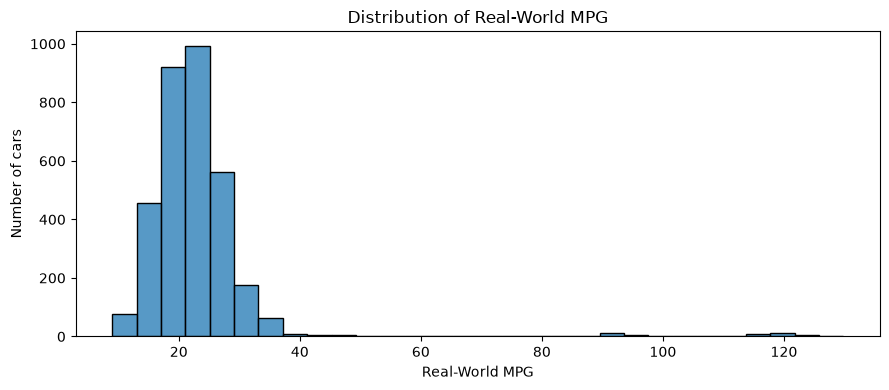

In [ ]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df_modelo, x="Real-World MPG", bins=30)
plt.title("Distribution of Real-World MPG")
plt.xlabel("Real-World MPG")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Boxplot of Real-World MPG')

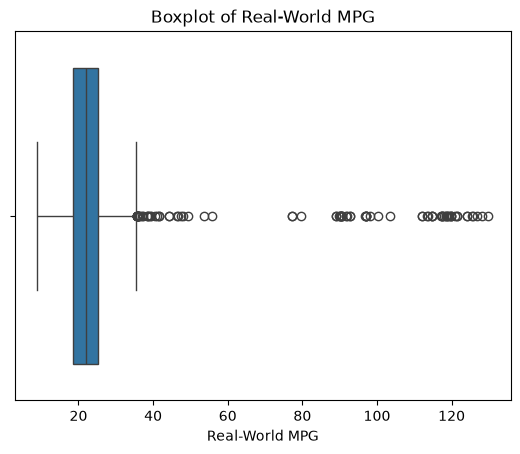

In [ ]:
sns.boxplot(df_modelo, x="Real-World MPG")
plt.title("Boxplot of Real-World MPG")

The next cell calculates the interquartile range limits for Real-World MPG and displays the rows outside those limits for review.

In [ ]:
q1 = df_modelo["Real-World MPG"].quantile(0.25)
q3 = df_modelo["Real-World MPG"].quantile(0.75)
riq = q3 - q1
limite_inferior = q1 - 1.5 * riq
limite_superior = q3 + 1.5 * riq

print(
    f"Limits for review: "
    f"{limite_inferior:.2f} to {limite_superior:.2f} MPG"
)

columnas_revisar = [
    "Manufacturer",
    "Model Year",
    "Vehicle Type",
    "Regulatory Class",
    "Real-World MPG",
    "Real-World MPG_City",
    "Real-World MPG_Hwy",
    "Weight (lbs)",
    "Engine Displacement",
    "Horsepower (HP)"
]

posibles_atipicos = df_modelo[
    (df_modelo["Real-World MPG"] < limite_inferior)
    | (df_modelo["Real-World MPG"] > limite_superior)
]

posibles_atipicos[columnas_revisar].sort_values(
    "Real-World MPG",
    ascending=False
)

posibles_atipicos[columnas_revisar].sort_values(
    "Real-World MPG",
    ascending=True
)

Limits for review: 8.15 to 35.54 MPG


,Manufacturer,Model Year,Vehicle Type,Regulatory Class,Real-World MPG,Real-World MPG_City,Real-World MPG_Hwy,Weight (lbs),Engine Displacement,Horsepower (HP)
4984,Toyota,2024,Minivan/Van,Truck,35.57107,35.11257,35.92495,5000.000,151.7659,189.0000
2189,Hyundai,2022,Sedan/Wagon,Car,35.63606,31.19128,39.92838,3331.214,118.4398,173.3077
4983,Toyota,2023,Minivan/Van,Truck,35.65454,35.18400,36.01792,5000.000,151.7659,189.0000
4985,Toyota,2025,Minivan/Van,Truck,35.66157,35.21622,36.00506,5000.000,151.7659,189.0000
5513,VW,2021,Car SUV,Car,35.66820,32.38181,38.62543,4719.100,181.2831,382.6406
...,...,...,...,...,...,...,...,...,...,...
4792,Tesla,2024,Sedan/Wagon,Car,125.51497,133.32002,120.20612,4052.089,NaN,379.0476
4790,Tesla,2022,Sedan/Wagon,Car,125.69758,131.12016,121.89468,4079.846,NaN,422.6195
4791,Tesla,2023,Sedan/Wagon,Car,126.83303,133.16972,122.43795,4043.594,NaN,329.8641
4793,Tesla,2025,Sedan/Wagon,Car,128.25440,136.46891,122.68347,4018.633,NaN,363.2086


The following cell creates df_modelo_noEV by keeping rows where all listed electrified powertrain categories have a value of zero.
Then calculates descriptive statistics and draws a boxplot for `Real-World MPG` in `df_modelo_noEV`.

Rows in original df_modelo: 3323
Rows without hybrid or electric shares: 2502
Rows excluded: 821
Number of observations: 2502
Minimum: 8.99 MPG
Q1 (25%): 17.51 MPG
Median (Q2, 50%): 20.75 MPG
Q3 (75%): 23.42 MPG
Interquartile range (Q3 - Q1): 5.91 MPG
Limits for possible outliers: 8.64 to 32.29 MPG
Boxplot whiskers: 8.99 to 32.22 MPG
Possible outliers: 7


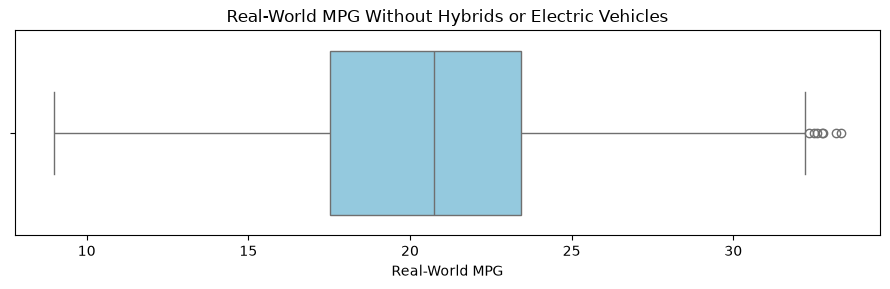

In [ ]:
categorias_electrificadas = [
    "Powertrain - Gasoline Mild Hybrid/MHEV",
    "Powertrain - Gasoline Strong Hybrid/HEV",
    "Powertrain - Battery Electric Vehicle (BEV)",
    "Powertrain - Plug-in Hybrid Electric Vehicle (PHEV)",
    "Powertrain - Fuel Cell Electric Vehicle (FCEV)"
]

mask_noEV = df_modelo[categorias_electrificadas].eq(0).all(axis=1)
df_modelo_noEV = df_modelo.loc[mask_noEV].copy()

print(f"Rows in original df_modelo: {len(df_modelo)}")
print(f"Rows without hybrid or electric shares: {len(df_modelo_noEV)}")
print(f"Rows excluded: {len(df_modelo) - len(df_modelo_noEV)}")

mpg_noEV = df_modelo_noEV["Real-World MPG"].dropna()
q1_noEV = mpg_noEV.quantile(0.25)
mediana_noEV = mpg_noEV.quantile(0.50)
q3_noEV = mpg_noEV.quantile(0.75)
riq_noEV = q3_noEV - q1_noEV
limite_inferior_noEV = q1_noEV - 1.5 * riq_noEV
limite_superior_noEV = q3_noEV + 1.5 * riq_noEV
valores_no_atipicos = mpg_noEV[
    (mpg_noEV >= limite_inferior_noEV)
    & (mpg_noEV <= limite_superior_noEV)
]

print(f"Number of observations: {len(mpg_noEV)}")
print(f"Minimum: {mpg_noEV.min():.2f} MPG")
print(f"Q1 (25%): {q1_noEV:.2f} MPG")
print(f"Median (Q2, 50%): {mediana_noEV:.2f} MPG")
print(f"Q3 (75%): {q3_noEV:.2f} MPG")
print(f"Interquartile range (Q3 - Q1): {riq_noEV:.2f} MPG")
print(
    f"Limits for possible outliers: "
    f"{limite_inferior_noEV:.2f} to {limite_superior_noEV:.2f} MPG"
)
print(
    f"Boxplot whiskers: "
    f"{valores_no_atipicos.min():.2f} to "
    f"{valores_no_atipicos.max():.2f} MPG"
)
print(
    "Possible outliers:",
    (~mpg_noEV.between(limite_inferior_noEV, limite_superior_noEV)).sum()
)

plt.figure(figsize=(9, 3))
sns.boxplot(x=mpg_noEV, color="skyblue")
plt.title("Real-World MPG Without Hybrids or Electric Vehicles")
plt.xlabel("Real-World MPG")
plt.tight_layout()
plt.show()

This cell displays the possible Real-World MPG outliers in df_modelo_noEV, ordered from lowest to highest.

In [ ]:
mask_atipicos_noEV = (
    (df_modelo_noEV["Real-World MPG"] < limite_inferior_noEV)
    | (df_modelo_noEV["Real-World MPG"] > limite_superior_noEV)
)

columnas_atipicos_noEV = [
    "Manufacturer",
    "Model Year",
    "Vehicle Type",
    "Real-World MPG",
    "Weight (lbs)",
    "Engine Displacement",
    "Horsepower (HP)",
    "Powertrain - Other (incl. CNG)"
]

atipicos_noEV = df_modelo_noEV.loc[
    mask_atipicos_noEV,
    columnas_atipicos_noEV
].sort_values("Real-World MPG", ascending=True)

print(f"Possible outliers found: {len(atipicos_noEV)}")
atipicos_noEV

Possible outliers found: 7


,Manufacturer,Model Year,Vehicle Type,Real-World MPG,Weight (lbs),Engine Displacement,Horsepower (HP),Powertrain - Other (incl. CNG)
3741,Nissan,2022,Car SUV,32.34187,3686.427,95.4601,209.6177,0.0
2948,Mazda,2016,Sedan/Wagon,32.48981,3123.836,132.2513,163.7314,0.0
2947,Mazda,2015,Sedan/Wagon,32.58697,3185.374,135.0643,167.5990,0.0
3743,Nissan,2024,Car SUV,32.75942,3907.122,93.7253,205.8084,0.0
2548,Kia,2024,Sedan/Wagon,32.77665,3103.103,117.4939,157.6919,0.0
3742,Nissan,2023,Car SUV,33.16246,3868.522,92.5546,203.2376,0.0
5576,VW,1982,Pickup,33.32250,2309.755,98.9122,58.0665,0.0


This cell counts the rows in df_modelo_noEV where the Powertrain - Other (incl. CNG) share is greater than 1%.

The original notebook also includes this note: “The natural gas car sample is so small that it will not affect the model.”

In [ ]:
mask_other_mayor_1 = (
    df_modelo_noEV["Powertrain - Other (incl. CNG)"] > 0.01
)

filas_other_mayor_1 = int(mask_other_mayor_1.sum())
porcentaje_other_mayor_1 = mask_other_mayor_1.mean() * 100

print(f"Rows with Other > 1%: {filas_other_mayor_1}")
print(f"Percentage of df_modelo_noEV: {porcentaje_other_mayor_1:.2f}%")

Rows with Other > 1%: 0
Percentage of df_modelo_noEV: 0.00%


The following scatterplots show Real-World MPG against weight, engine displacement, horsepower, and model year in df_modelo_noEV.

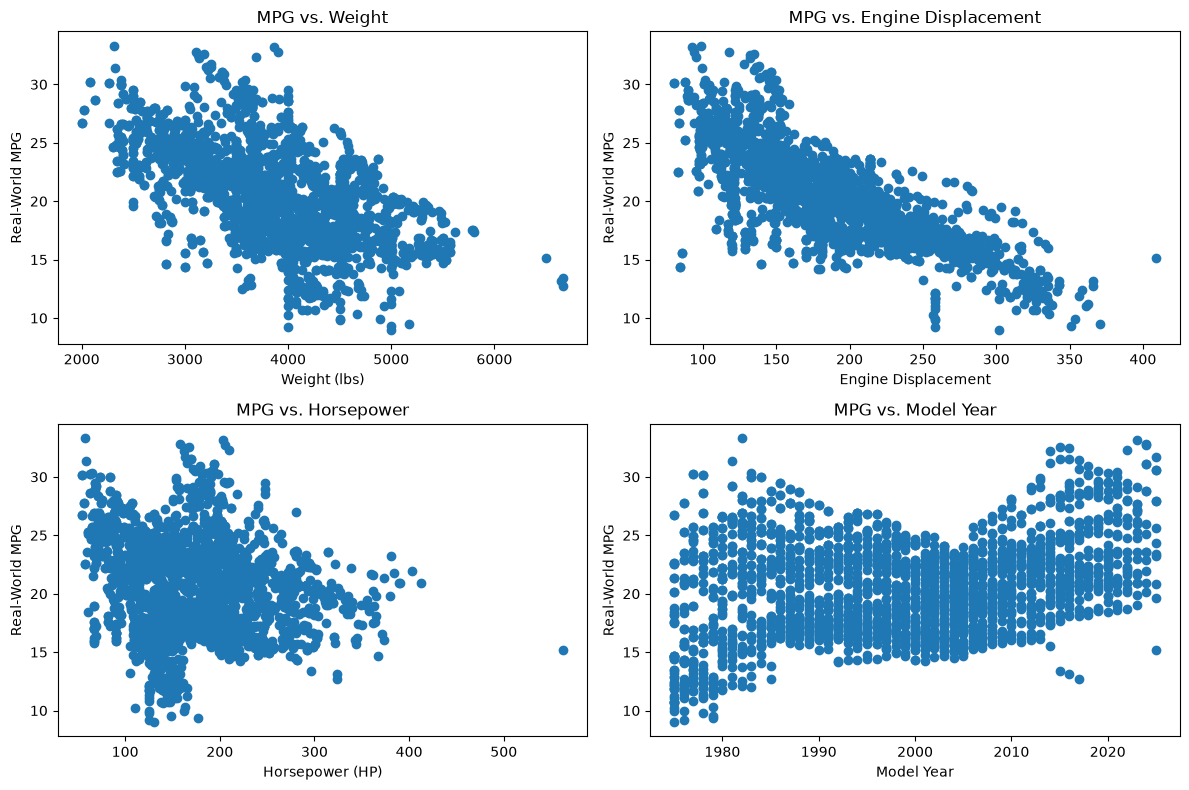

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# MPG vs. Weight
axes[0, 0].scatter(
    df_modelo_noEV["Weight (lbs)"],
    df_modelo_noEV["Real-World MPG"]
)
axes[0, 0].set_title("MPG vs. Weight")
axes[0, 0].set_xlabel("Weight (lbs)")
axes[0, 0].set_ylabel("Real-World MPG")

# MPG vs. Engine Displacement
axes[0, 1].scatter(
    df_modelo_noEV["Engine Displacement"],
    df_modelo_noEV["Real-World MPG"]
)
axes[0, 1].set_title("MPG vs. Engine Displacement")
axes[0, 1].set_xlabel("Engine Displacement")
axes[0, 1].set_ylabel("Real-World MPG")

# MPG vs. Horsepower
axes[1, 0].scatter(
    df_modelo_noEV["Horsepower (HP)"],
    df_modelo_noEV["Real-World MPG"]
)
axes[1, 0].set_title("MPG vs. Horsepower")
axes[1, 0].set_xlabel("Horsepower (HP)")
axes[1, 0].set_ylabel("Real-World MPG")

# MPG vs. Model Year
axes[1, 1].scatter(
    pd.to_numeric(df_modelo_noEV["Model Year"], errors="coerce"),
    df_modelo_noEV["Real-World MPG"]
)
axes[1, 1].set_title("MPG vs. Model Year")
axes[1, 1].set_xlabel("Model Year")
axes[1, 1].set_ylabel("Real-World MPG")

plt.tight_layout()
plt.show()

The heatmap shows correlations between Real-World MPG, weight, engine displacement, horsepower, and model year. The Start/Stop variable is excluded.

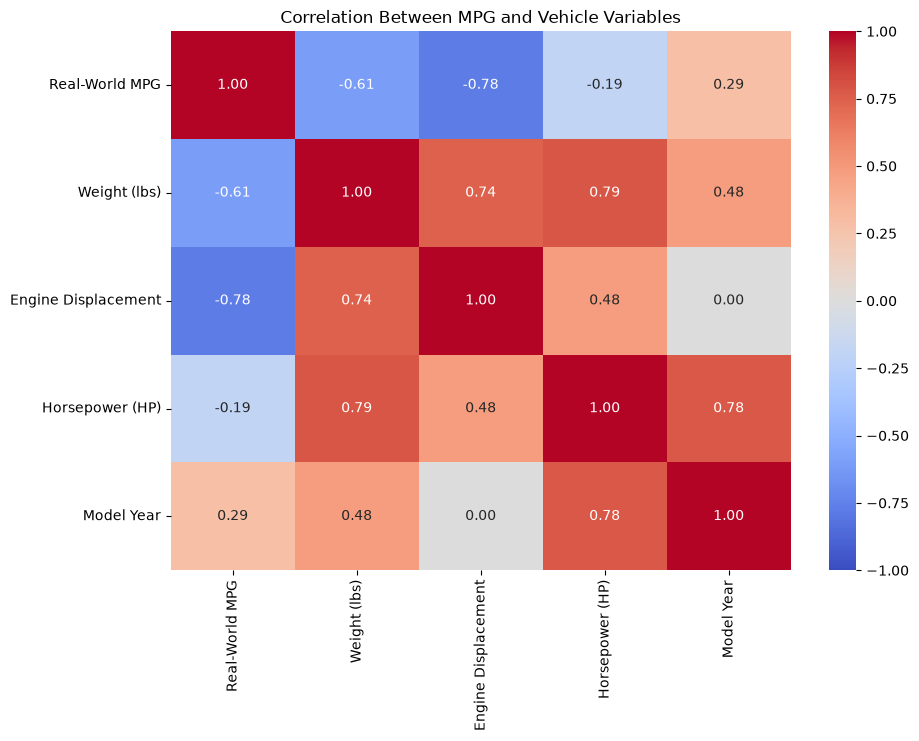

In [ ]:
columnas_heatmap = [
    "Real-World MPG",
    "Weight (lbs)",
    "Engine Displacement",
    "Horsepower (HP)",
    "Model Year"
]

datos_heatmap = df_modelo_noEV[columnas_heatmap].copy()

for columna in columnas_heatmap:
    datos_heatmap[columna] = pd.to_numeric(
        datos_heatmap[columna],
        errors="coerce"
    )

correlaciones = datos_heatmap.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Between MPG and Vehicle Variables")
plt.show()

#### Linear Regression
<!-- Fit the model on training data and predict on test data. Use only variables available at prediction time. -->
The model uses "Weight (lbs)" as the only predictor because it is a vehicle characteristic available when making a prediction. The target is "Real-World MPG".  
Other MPG columns are not used as predictors.

In [ ]:
from sklearn.linear_model import LinearRegression

columnas_regresion_simple = [
    "Model Year",
    "Weight (lbs)",
    "Real-World MPG"
]

df_regresion_simple = df_modelo_noEV[
    columnas_regresion_simple
].copy()

for columna in columnas_regresion_simple:
    df_regresion_simple[columna] = pd.to_numeric(
        df_regresion_simple[columna],
        errors="coerce"
    )

filas_antes = len(df_regresion_simple)

df_regresion_simple = df_regresion_simple.dropna(
    subset=columnas_regresion_simple
).copy()

print("Rows removed because a required value was missing:",
      filas_antes - len(df_regresion_simple))

Rows removed because a required value was missing: 0


The data is split by model year to preserve time order. Models before 2020 are used for training, and models from 2020 onward are used for testing.

In [ ]:
training_rows = df_regresion_simple["Model Year"] < 2020
test_rows = df_regresion_simple["Model Year"] >= 2020

X_train = df_regresion_simple.loc[
    training_rows,
    ["Weight (lbs)"]
].copy()

X_test = df_regresion_simple.loc[
    test_rows,
    ["Weight (lbs)"]
].copy()

y_train = df_regresion_simple.loc[
    training_rows,
    "Real-World MPG"
].copy()

y_test = df_regresion_simple.loc[
    test_rows,
    "Real-World MPG"
].copy()

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 2367
Test rows: 135


The model is fitted using the training data. It then predicts "Real-World MPG" for the test data.

In [ ]:
modelo_simple = LinearRegression()

modelo_simple.fit(X_train, y_train)

mpg_predicho = modelo_simple.predict(X_test)

This table shows the actual and predicted MPG values for the test data.

In [ ]:
predicciones_simple = pd.DataFrame({
    "Actual MPG": y_test,
    "Predicted MPG": mpg_predicho
}, index=y_test.index)

display(predicciones_simple.head())

,Actual MPG,Predicted MPG
606,29.49066,19.682951
607,28.98645,19.682951
608,25.84652,17.887845
609,25.96255,17.887845
610,25.96245,17.887845


The scatterplot shows the training data and the fitted linear regression line. Weight is measured in pounds, and the target is Real-World MPG.

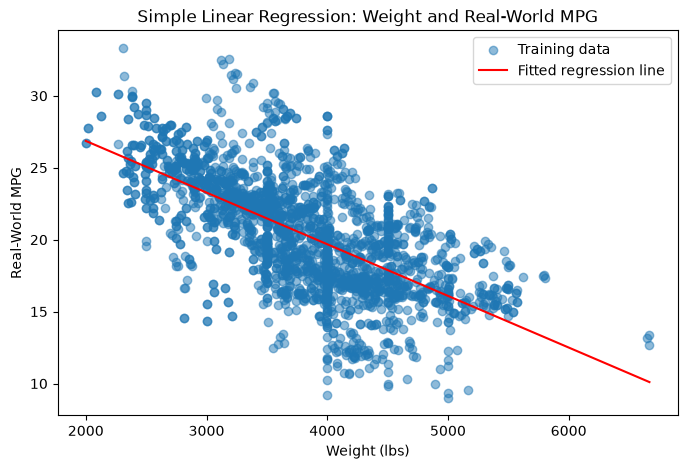

In [ ]:
x_line = pd.DataFrame({
    "Weight (lbs)": [
        X_train["Weight (lbs)"].min(),
        X_train["Weight (lbs)"].max()
    ]
})

mpg_line = modelo_simple.predict(x_line)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_train["Weight (lbs)"],
    y_train,
    alpha=0.5,
    label="Training data"
)
plt.plot(
    x_line["Weight (lbs)"],
    mpg_line,
    color="red",
    label="Fitted regression line"
)
plt.title("Simple Linear Regression: Weight and Real-World MPG")
plt.xlabel("Weight (lbs)")
plt.ylabel("Real-World MPG")
plt.legend()
plt.show()

#### Evaluation
<!-- Report test MAE and R², and plot actual against predicted values. Compare MAE with a baseline that always predicts the training target mean. Explain the error in the units of the problem.

The Mean Absolute Error (MAE) measures the average prediction error in MPG.  
The baseline always predicts the mean "Real-World MPG" from the training data.   
We compare the models test MAE with this baseline and report the test R².

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

mae_test = mean_absolute_error(y_test, mpg_predicho)
r2_test = r2_score(y_test, mpg_predicho)

prediccion_baseline = y_train.mean()
mpg_baseline = [prediccion_baseline] * len(y_test)
mae_baseline = mean_absolute_error(y_test, mpg_baseline)

print(f"Test MAE: {mae_test:.2f} MPG")
print(f"Baseline MAE: {mae_baseline:.2f} MPG")
print(f"Test R²: {r2_test:.3f}")

Test MAE: 5.89 MPG
Baseline MAE: 4.62 MPG
Test R²: -1.799


The plot compares actual and predicted "Real-World MPG" values for the test data. The dashed line represents perfect predictions.

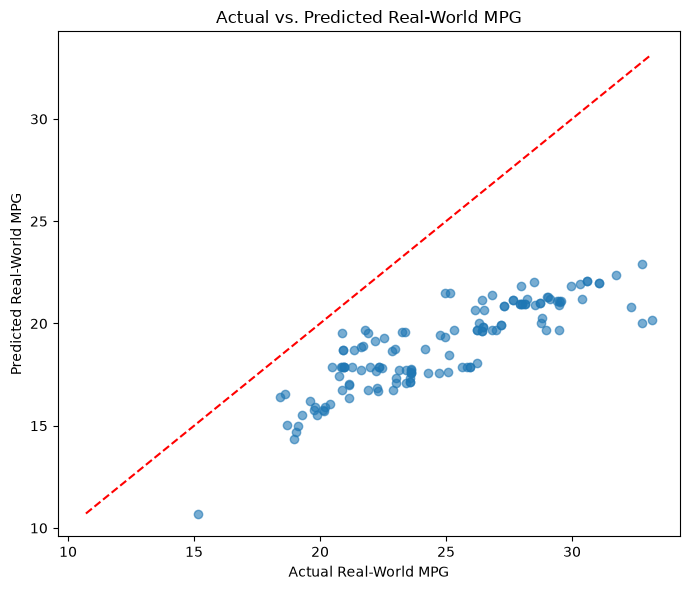

In [ ]:
valor_minimo = min(y_test.min(), mpg_predicho.min())
valor_maximo = max(y_test.max(), mpg_predicho.max())

plt.figure(figsize=(7, 6))
plt.scatter(y_test, mpg_predicho, alpha=0.6)
plt.plot(
    [valor_minimo, valor_maximo],
    [valor_minimo, valor_maximo],
    linestyle="--",
    color="red"
)
plt.title("Actual vs. Predicted Real-World MPG")
plt.xlabel("Actual Real-World MPG")
plt.ylabel("Predicted Real-World MPG")
plt.tight_layout()
plt.show()

#### Conclusions

On the test data, the model's MAE was 5.89 MPG, compared with 4.62 MPG for the training-mean baseline.   
This means the model's average absolute error was 1.27 MPG higher than the baseline.   
The model did not improve on the baseline.
Its test R² was -1.799, indicating poor performance on the test data.
The actual-versus-predicted plot shows that many predictions fall below the reference line, particularly for higher actual MPG values. The predictions also cover a narrower range than the actual values. Using vehicle weight alone does not capture enough information to predict MPG well for these later model years.

This model has two main limitations: it uses only one predictor, so it does not capture the effects of other vehicle characteristics.   
Also, the dataset contains grouped vehicle records rather than individual cars.   
One improvement would be to use a multiple linear regression with additional prediction-time variables from the notebook, such as model year, engine displacement, and horsepower.   
MPG-derived columns should remain excluded as predictors. 
The test set contains later model years than the training set, which evaluates performance across time.

We used AI to help draft and organize code.
